# Comparison with CLASS

A validation run for a cosmology with one massive neutrino: the power spectra of the cold dark matter and the baryons against CLASS, at redshift 99, where N-body initial conditions are often set, and at redshift 0.

CLASS (`classy`), scipy and matplotlib come with the project's dev group.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from classy import Class
from scipy.interpolate import CubicSpline

from discoeb import LCDM_MNU, background_history, solve_eb

K = np.geomspace(1.0e-4, 1.0, 128)  # wave numbers, 1/Mpc
REDSHIFTS = (99.0, 0.0)

## The cosmology

`LCDM_MNU` adds massive neutrinos to `LCDM`. `Omegam` counts the cold dark matter and the baryons.

In [2]:
h = 0.67742
cosmology = LCDM_MNU(
    Omegam=0.3099,  # CDM and baryons
    Omegab=0.0488911,
    H0=100.0 * h,
    A_s=2.1064e-9,
    n_s=0.96822,
    Tcmb=2.7255,
    YHe=0.248,
    Neff=2.046,  # the massless flavours
    Nmnu=1,
    mnu=0.06,  # eV
)

## From a density contrast to a spectrum

DISCO-EB's solutions and CLASS's transfer functions are both per unit primordial curvature, so for either code

$$
P_i(k) = \frac{2 \pi^2}{k^3} A_s \left(\frac{k}{k_p}\right)^{n_s - 1} \delta_i(k)^2 ,
$$

and the two species together have the density-weighted contrast.

In [3]:
def spectrum(delta):
    primordial = cosmology.A_s * (K / cosmology.k_p) ** (cosmology.n_s - 1.0)
    return 2.0 * np.pi**2 / K**3 * primordial * delta**2

## DISCO-EB

`background_history` gives the conformal times of the two redshifts. One launch then keeps the two contrasts at both.

In [4]:
# DISCO-EB: the conformal times of the redshifts, then one launch.
a_bg, tau_bg = background_history(cosmology)
tau = np.interp(1.0 / (1.0 + np.asarray(REDSHIFTS)), a_bg, tau_bg)
values = solve_eb(cosmology, K, tau, keep=("clxc", "clxb"), rtol=1.0e-5)
clxc, clxb = np.asarray(values[0])  # each (k, redshift)
f_b = cosmology.Omegab / cosmology.Omegam  # baryon share of the two
disco = {
    "CDM": spectrum(clxc.T),
    "baryons": spectrum(clxb.T),
    "CDM + baryons": spectrum(((1.0 - f_b) * clxc + f_b * clxb).T),
}  # each (redshift, k)

## CLASS

The same cosmology in the synchronous gauge, without reionization and with the full neutrino hierarchy.

In [5]:
# CLASS: the same cosmology, without reionization.
reference = Class()
reference.set(
    {
        "h": h,
        "Omega_b": cosmology.Omegab,
        "Omega_cdm": cosmology.Omegam - cosmology.Omegab,
        "T_cmb": cosmology.Tcmb,
        "YHe": cosmology.YHe,
        "N_ur": cosmology.Neff,
        "N_ncdm": 1,
        "m_ncdm": cosmology.mnu,
        "reio_parametrization": "reio_none",
        "output": "dTk",
        "gauge": "synchronous",
        "P_k_max_1/Mpc": 1.1 * K[-1],
        "z_max_pk": max(REDSHIFTS),
        "k_per_decade_for_pk": 50,
        "k_per_decade_for_bao": 50,
        "ncdm_fluid_approximation": 3,  # none: integrate the full hierarchy
    }
)
reference.compute()

A cubic spline in $\ln k$ brings CLASS's transfer functions onto DISCO-EB's wave numbers. A linear interpolation would leave its own wiggles at the BAO.

In [6]:
classy = {name: [] for name in disco}
for z in REDSHIFTS:
    transfer = reference.get_transfer(z)
    k_class = transfer["k (h/Mpc)"] * h
    d_c, d_b = (
        CubicSpline(np.log(k_class), transfer[c])(np.log(K)) for c in ("d_cdm", "d_b")
    )
    for name, delta in zip(classy, (d_c, d_b, (1.0 - f_b) * d_c + f_b * d_b)):
        classy[name].append(spectrum(delta))

## The comparison

The grey band is one per cent.

           species      z   max |P / P_CLASS - 1|
               CDM     99                2.58e-03
           baryons     99                3.71e-03
     CDM + baryons     99                2.71e-03
               CDM      0                2.88e-03
           baryons      0                2.90e-03
     CDM + baryons      0                2.89e-03


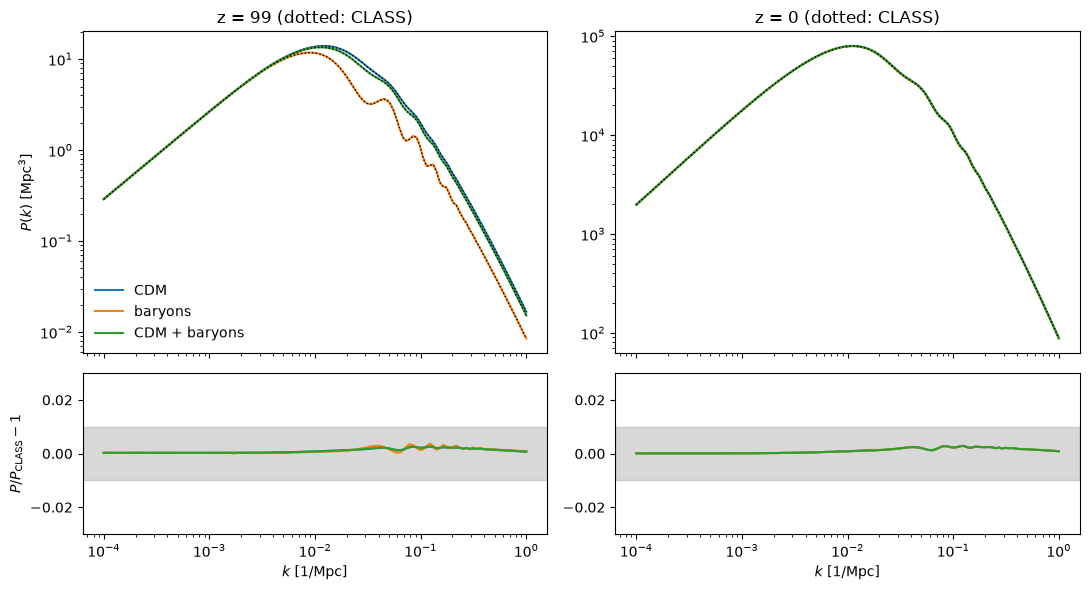

In [7]:
fig, axes = plt.subplots(
    2, len(REDSHIFTS), figsize=(11, 6), sharex=True, height_ratios=(2, 1)
)
print(f"{'species':>18}  {'z':>5}  {'max |P / P_CLASS - 1|':>22}")
for j, z in enumerate(REDSHIFTS):
    for color, name in zip(("C0", "C1", "C2"), disco):
        ratio = disco[name][j] / classy[name][j] - 1.0
        print(f"{name:>18}  {z:5.0f}  {np.abs(ratio).max():22.2e}")
        axes[0, j].loglog(K, disco[name][j], color=color, label=name)
        axes[0, j].loglog(K, classy[name][j], color="k", ls=":", lw=1)
        axes[1, j].semilogx(K, ratio, color=color)
    axes[0, j].set_title(f"z = {z:.0f} (dotted: CLASS)")
    axes[1, j].axhspan(-0.01, 0.01, color="gray", alpha=0.3)
    axes[1, j].set_ylim(-0.03, 0.03)
    axes[1, j].set_xlabel(r"$k$ [1/Mpc]")
axes[0, 0].set_ylabel(r"$P(k)$ [Mpc$^3$]")
axes[1, 0].set_ylabel(r"$P / P_\mathrm{CLASS} - 1$")
axes[0, 0].legend(frameon=False)
fig.tight_layout()
plt.show()